<a href="https://colab.research.google.com/github/covinolab/sbi_tutorial_algosb2026/blob/main/solutions/01_sbi_toy_2d_solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SBI from scratch on a 2D toy problem

**AlgoSB 2026 · simulation-based inference · hands-on notebook 1 of 2 · 75 minutes**

This morning you heard how simulation-based inference (SBI) turns a simulator into a posterior. Now you do it yourself, on a problem small enough that the exact posterior is known. That exact posterior is your **answer key**: whatever you build, you can compare with it.

| Part | Min | Your challenge |
| --- | --- | --- |
| 0 | 5 | Setup and the three ingredients |
| 1 | 12 | Inference by hand, then by a loop |
| 2 | 18 | Train a posterior that matches the answer key |
| 3 | 10 | Find the hidden walls of a black-box network |
| 4 | 12 | Which network lies? |
| 5 | 13 | Pin θ down with 100 observations |
| 6 | 5 | Wrap-up |

**How it works**

- Every part is a challenge. A check cell scores what you built and prints ✅ PASS or ❌ NOT YET.
- How you get there is up to you: trial and error, changing the given code, thinking, or asking an LLM for code. The check is what counts.
- Every `sbi` call you need appears once in a worked cell. Copy it from there.
- After a pass, write one sentence on why it worked. We discuss each part in the room.
- Stuck? Ask us. Worked answers with the reasoning are in `solutions/`.

> **Solutions notebook.** Same notebook as the students', with every challenge solved. Each answer comes with the reasoning and with the message the part is meant to carry.

In [1]:
# Setup. On Colab this installs sbi and fetches the tutorial files; on your own machine it only
# steps up from solutions/ to the folder that holds tutorial_utils.py.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("tutorial_utils.py"):
    !pip install -q sbi==0.27.0
    !git clone -q --depth 1 https://github.com/covinolab/sbi_tutorial_algosb2026.git
    %cd sbi_tutorial_algosb2026
elif not os.path.exists("tutorial_utils.py"):
    os.chdir("..")

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch

import sbi
from sbi.inference import NLE, NPE
from sbi.neural_nets import posterior_nn
from sbi.utils import BoxUniform

import tutorial_utils as tu
from tutorial_utils import (ExactPosterior, check_by_hand, check_calibration, check_iid,
                            check_match, check_walls, interval_width, plot_cloud, plot_posteriors)

warnings.filterwarnings("ignore")  # sbi is talkative; none of its warnings matter today
tu.set_plot_style()
torch.manual_seed(0)
np.random.seed(0)
print(f"sbi {sbi.__version__} · torch {torch.__version__}")

sbi 0.27.0 · torch 2.15.0+cu132


## Part 0 · Setup and the three ingredients (5 min)

SBI needs three things from you.

1. A **prior** $p(\theta)$: what you know about the parameters before you see data.
2. A **simulator**: a program that turns parameters $\theta$ into data $x$. Running it draws $x \sim p(x \mid \theta)$. You never have to write down or evaluate that likelihood.
3. An **observation** $x_o$: the data you want explained.

From these you want the **posterior** $p(\theta \mid x_o)$: the parameters that could have produced $x_o$, each weighted by how plausible it is.

Both notebooks follow the same five steps with the same names:

| Step | In the code |
| --- | --- |
| 1. Prior | `prior` |
| 2. Simulator | `simulator(theta)` returns `x` |
| 3. Training set | `theta`, `x` |
| 4. Training | `posterior` |
| 5. Inference and checks | `x_o`, `samples` |

In [3]:
# 1. Prior: each of the two parameters lies somewhere between -5 and 5
prior = BoxUniform(low=-5 * torch.ones(2), high=5 * torch.ones(2))

# 2. Simulator: one noisy 2D point around theta
def simulator(theta):
    return theta + 0.5 * torch.randn_like(theta)

# The observation: one 2D point. Somebody ran the simulator once, at a theta you are not told.
x_o = tu.load_toy_observations()[0]

LIMITS = [[-5, 5], [-5, 5]]
print("x_o =", x_o)

x_o = tensor([ 2.4466, -1.2309])


In [4]:
# A first look: draw five parameters from the prior and simulate a data point for each
theta_demo = prior.sample((5,))
x_demo = simulator(theta_demo)
for t, x_ in zip(theta_demo, x_demo):
    print(f"theta = ({t[0]:5.2f}, {t[1]:5.2f})   ->   x = ({x_[0]:5.2f}, {x_[1]:5.2f})")

theta = (-0.04,  2.68)   ->   x = ( 0.04,  2.38)
theta = (-4.12, -3.68)   ->   x = (-4.51, -3.15)
theta = (-1.93,  1.34)   ->   x = (-2.06,  1.87)
theta = (-0.10,  3.96)   ->   x = ( 0.11,  4.38)
theta = (-0.44,  1.32)   ->   x = (-0.86,  0.93)


**Warm-up, no check.** Name the three ingredients in the cells above: which line is the prior, which the simulator, which the observation? What would each of the three be in your own research?

**Answer.** `prior` is the prior: a uniform box, the only thing known about θ before any data. `simulator` is the simulator: it adds Gaussian noise of standard deviation 0.5 to θ, so here θ is the unknown mean of a 2D Gaussian. `x_o` is the observation. In a lab, the observation is the measurement, the simulator is the model of the experiment including its noise, and the prior is the range of parameters you would not be surprised by.

## Part 1 · Inference by hand, then by a loop (12 min)

The simulator runs forward: from θ to x. Inference is the way back: which θ could have produced $x_o$? Do it by hand first.

**Challenge 1a: the best θ.** Pick a θ, simulate a cloud of points, compare the cloud with $x_o$, adjust. Find a θ whose cloud lands on $x_o$.

**Challenge 1b: the furthest θ.** Now move away from your best θ. Find a second θ, as far from the first as you can, that could still have produced $x_o$.

**Passes when** the centre of the best cloud lies within 0.1 of $x_o$, and the furthest θ is at least 1.0 away from the best and still inside the 95% region of the answer key.

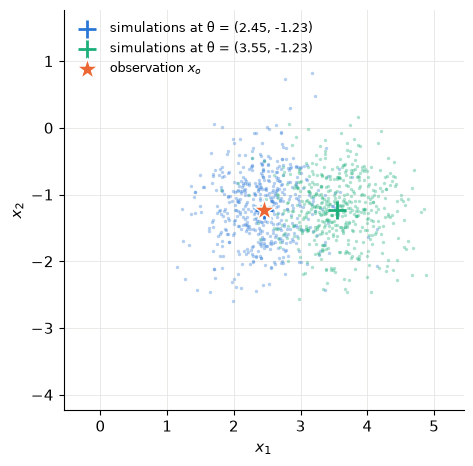

In [5]:
theta_best = x_o.clone()                           # the cloud is centred on theta, so theta = x_o fits best
theta_far = x_o + torch.tensor([1.1, 0.0])         # 1.1 away: x_o sits at the rim of this cloud
plot_cloud([theta_best, theta_far], x_o, simulator, zoom=3);

In [6]:
check_by_hand(theta_best, theta_far, x_o)

✅ PASS · Part 1 · best θ · cloud centre is 0.01 from x_o (target ≤ 0.1)
✅ PASS · Part 1 · furthest θ · 1.10 from your best θ and still inside the 95% region


**Why it works.** The simulator puts a cloud of standard deviation 0.5 around θ. The cloud is centred on $x_o$ when θ = $x_o$, so that is the best fit. But $x_o$ is a single noisy point: any θ whose cloud still reaches $x_o$ could have produced it. A point 1.1 away from the centre of a 2D Gaussian with standard deviation 0.5 is at 2.2 standard deviations, close to the rim: 95% of the cloud lies within 1.22. So the plausible parameters form a disc around $x_o$, and the furthest θ marks its edge.

Trial and error is not needed for the best θ once you see that the cloud is centred on θ. For the furthest θ, the check cell tells you when you went too far.

### The same search, done properly: a loop

You tried parameters, simulated, compared with $x_o$, and kept what fit. A loop can do the trying:

1. draw θ from the prior,
2. run the simulator once,
3. measure the distance between the simulated point and $x_o$,
4. keep θ if the distance is below a tolerance ε.

The kept parameters are samples from an approximate posterior. This is **rejection ABC** (approximate Bayesian computation). It needs no likelihood, only a simulator and a distance. This cell is a worked add-on without a check: run it and read it.

In [7]:
epsilon = 0.3

kept = []
for _ in range(100_000):
    theta = prior.sample()              # propose parameters
    x = simulator(theta)                # simulate one data point
    if torch.dist(x, x_o) < epsilon:    # distance to the observation
        kept.append(theta)              # close enough: keep
kept = torch.stack(kept)

print(f"kept {len(kept)} of 100,000 simulations ({len(kept) / 1000:.2f}%)")

kept 273 of 100,000 simulations (0.27%)


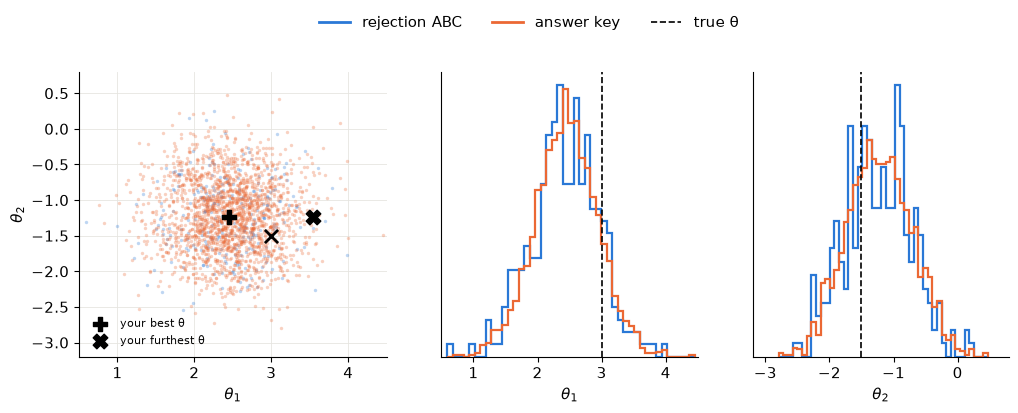

In [8]:
# The kept parameters next to the answer key. Now it can be told: x_o was simulated at theta = (3, -1.5).
theta_true = torch.tensor([3.0, -1.5])
exact = ExactPosterior(x_o)                        # the answer key for x_o

axes = plot_posteriors([kept, exact.sample((2000,))], ["rejection ABC", "answer key"],
                       truth=theta_true, limits=[[0.5, 4.5], [-3.2, 0.8]])
axes[0].scatter(*theta_best, marker="P", s=110, color="black", label="your best θ")
axes[0].scatter(*theta_far, marker="X", s=110, color="black", label="your furthest θ")
axes[0].legend(loc="lower left", fontsize=8);

Your best θ sits in the middle of the kept cloud, your furthest θ at its rim. And the θ that $x_o$ was really simulated with is just one of the plausible parameters. It is not the best-fitting one.

The tolerance ε sets a trade-off: a large ε keeps parameters that are too far off, a small ε keeps almost nothing. Either way the loop throws most simulations away, and for a new observation it has to run again.

**Message of Part 1.** Inference is the inverse problem. Many parameters could have produced $x_o$, and the posterior is that set with weights. A loop that keeps the parameters whose simulations land near $x_o$ recovers it without a likelihood. This is rejection ABC, and it throws almost every simulation away: here about 0.3% are kept.

*For the discussion:* with ε = 0.3 the ABC posterior is about 4% wider than the answer key, because accepting anything within ε blurs the posterior. Halving ε removes most of the blur and keeps four times fewer samples. In two dimensions that is affordable. With a 5,000-frame trajectory as data (Notebook 2) no simulation ever lands near the observation.

## Part 2 · Train a posterior that matches (18 min)

Rejection ABC used 0.3% of its simulations. **Neural posterior estimation (NPE)** uses all of them: a neural network $q(\theta \mid x)$ is trained on pairs $(\theta, x)$ to return the distribution of θ for a given x. No likelihood is evaluated, and no simulation is thrown away. Once trained, the network answers for any observation without new simulations.

The cell below runs steps 3 to 5 of the recipe. It works, but its settings are poor.

**Challenge.** Change the code until your posterior matches the answer key. Then go for the record: how few simulations are enough?

**Passes when** the overlay shows your posterior on top of the answer key and the **mismatch score** confirms it at 0.55 or below. The mismatch score is a classifier two-sample test (`c2st` in `sbi.utils.metrics`): a classifier is trained to tell your samples from samples of the answer key. A score of 0.5 means it cannot tell them apart, 1.0 means it always can.

 Neural network successfully converged after 67 epochs.

  0%|          | 0/2000 [00:00<?, ?it/s]

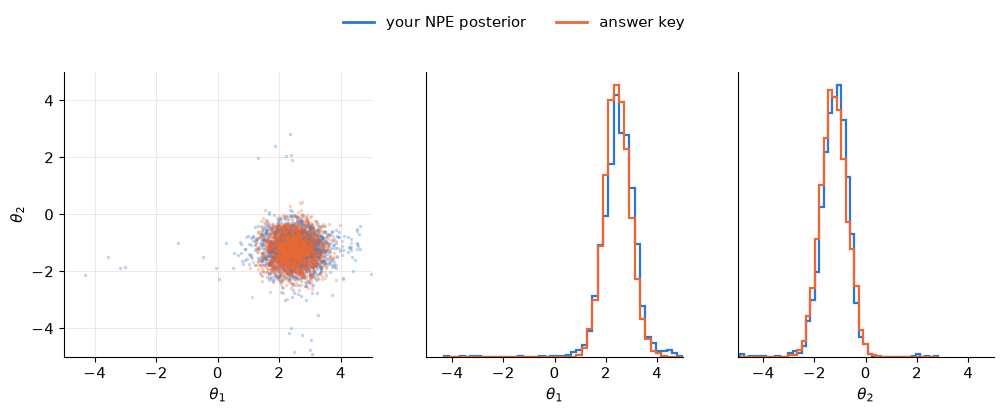

In [9]:
num_simulations = 2000

# 3. Training set: draw parameters from the prior and simulate one data point for each
theta = prior.sample((num_simulations,))
x = simulator(theta)

# 4. Training: a neural network learns q(theta | x) from the pairs
density_estimator = posterior_nn(model="nsf", hidden_features=50, num_transforms=5)   # sbi's defaults
inference = NPE(prior=prior, density_estimator=density_estimator)
inference.append_simulations(theta, x).train()
posterior = inference.build_posterior()

# 5. Inference: samples from q(theta | x_o)
samples = posterior.sample((2000,), x=x_o)

plot_posteriors([samples, exact.sample((2000,))], ["your NPE posterior", "answer key"], limits=LIMITS);

In [10]:
check_match(samples, num_simulations, x_o)

✅ PASS · Part 2 · match · mismatch score 0.52 (target ≤ 0.55) with 2,000 simulations


**Why it works.** Two things were wrong, and each alone keeps the check failing.

- *The network was too small.* One transform with two hidden units cannot express "the posterior mean follows x, in both coordinates, across the whole prior". With this network the mismatch stays above 0.8 for 50 as well as for 5,000 simulations. `hidden_features=50, num_transforms=5` are sbi's defaults; writing `density_estimator="nsf"` gives the same.
- *There were too few simulations.* 50 pairs do not show the network where the posterior sits for every x in a 10 × 10 box.

With the default network the score reaches 0.55 somewhere between 500 and 1,000 simulations and comes down to about 0.52 with 2,000. The cell below shows the curve, and how to get the record.

 Neural network successfully converged after 86 epochs.

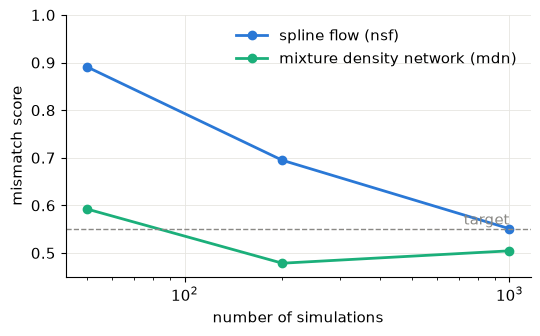

In [11]:
# How the mismatch falls with the number of simulations, for two density estimators.
def npe_mismatch(num_simulations, density_estimator):
    theta_ = prior.sample((num_simulations,))
    inference_ = NPE(prior=prior, density_estimator=density_estimator, show_progress_bars=False)
    inference_.append_simulations(theta_, simulator(theta_)).train()
    samples_ = inference_.build_posterior().sample((2000,), x=x_o, show_progress_bars=False)
    return tu.mismatch_score(samples_, exact.sample((2000,), seed=1))

counts = [50, 200, 1000]
fig, ax = plt.subplots(figsize=(6, 3.4))
for name, label, color in (("nsf", "spline flow (nsf)", tu.C_YOURS),
                           ("mdn", "mixture density network (mdn)", tu.C_OTHER)):
    ax.plot(counts, [npe_mismatch(n, name) for n in counts], "o-", lw=2, color=color, label=label)
ax.axhline(0.55, color=tu.C_MUTED, ls="--", lw=1)
ax.text(counts[-1], 0.56, "target", ha="right", color=tu.C_MUTED)
ax.set(xscale="log", xlabel="number of simulations", ylabel="mismatch score", ylim=(0.45, 1))
ax.legend();

**For the record.** "Flexible enough" does not mean "as flexible as possible". The true posterior here is a Gaussian whose mean follows x. A mixture density network (`density_estimator="mdn"`) builds that shape in, so it needs far fewer simulations than the spline flow: it often passes with about 100. sbi's default flow (`"maf"`) lies in between, at a few hundred. Knowing the shape of the answer buys simulations.

**How sharp is the mismatch score?** Not very, and it is worth saying so in the room. We distorted samples of the answer key on purpose and scored them:

| Samples of the answer key, but ... | Mismatch score |
| --- | --- |
| unchanged | 0.50 |
| 20% too wide | 0.51 |
| 30% too wide, or 20% too narrow | 0.53 |
| 50% too wide | 0.58 |
| shifted by 0.4 standard deviations | 0.57 |

So a pass at 0.55 means "within about 30% in width and a third of a standard deviation in position", not "identical". The overlay plot shows more than the number. A classifier needs many samples to see a small difference between two distributions, and Part 5 will ask for more: there the width has to be right within 25%.

**If a training run goes badly wrong.** With `"maf"` and 10,000 simulations, about one training run in ten gets stuck here and ignores one coordinate of x completely: one marginal stays as flat as the prior. The overlay shows it at once, and running the cell again fixes it. We never saw this with `"nsf"` or `"mdn"`, which is why the starting cell uses `"nsf"`.

**Message of Part 2.** The network learns the posterior from simulated pairs alone; no likelihood is ever evaluated. Its quality is bought with simulations, and the density estimator has to be flexible enough.

## Part 3 · Find the hidden walls (10 min)

Your network never saw $x_o$ during training, and still it answered. It answers for any observation. This is called **amortized** inference: you pay for the simulations and the training once, and every further observation is nearly free.

In [12]:
# Your posterior at three other observations, each scored against its own answer key
for x_other in ([0.0, 0.0], [-3.0, 2.0], [2.0, -4.0]):
    x_other = torch.tensor(x_other)
    samples_other = posterior.sample((2000,), x=x_other, show_progress_bars=False)
    score = tu.mismatch_score(samples_other, ExactPosterior(x_other).sample((2000,)))
    print(f"x = {x_other.tolist()}: mismatch score {score:.2f}")

x = [0.0, 0.0]: mismatch score 0.53
x = [-3.0, 2.0]: mismatch score 0.54
x = [2.0, -4.0]: mismatch score 0.55


Inside its prior, your network is about as good everywhere as it is at $x_o$. But where does that end?

Here is a second network, handed over as a **black box**. Somebody else trained it for the same simulator, with a prior you are not told. All you can do is ask it for samples.

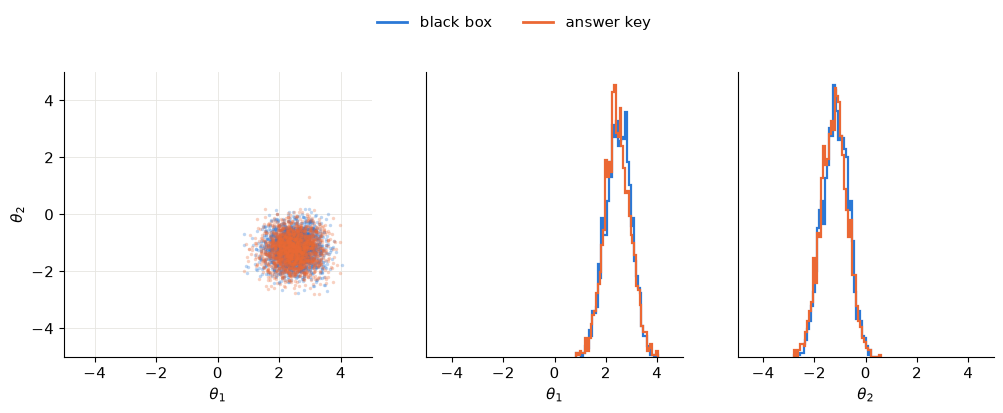

In [13]:
black_box = tu.load_black_box()

probe = black_box.sample((2000,), x=x_o)
plot_posteriors([probe, exact.sample((2000,))], ["black box", "answer key"], limits=LIMITS);

At $x_o$ the black box agrees with the answer key. It looks trustworthy.

**Challenge.** Find out where the black box can be trusted: locate the four edges of its training prior.

**Passes when** all four edges are located to within 0.3.

Probe the black box, not your own network from Part 2. Far outside its prior a network may put all its samples outside the prior, and `sbi`, which throws those away and draws again, then never finishes. The black box has a time limit built in. Bonus 2 shows how to set one yourself.

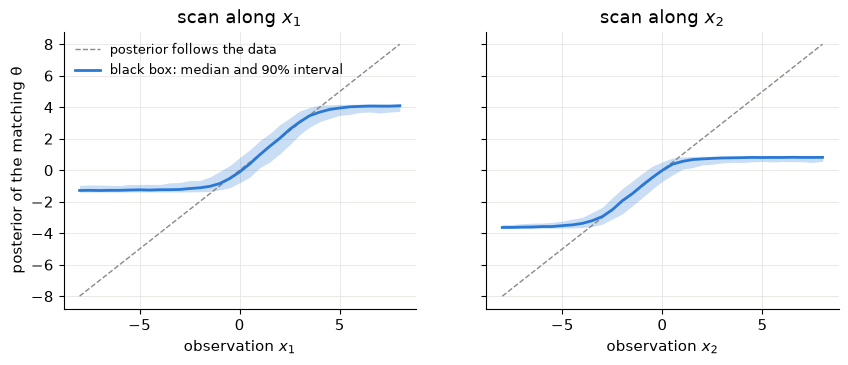

In [14]:
# Scan: move the observation along x_1 (then along x_2) and watch where the posterior stops following.
scan = torch.linspace(-8, 8, 33)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for d, ax in enumerate(axes):
    quantiles = []
    for value in scan:
        x_probe = x_o.clone()
        x_probe[d] = value
        probe = black_box.sample((500,), x=x_probe)
        quantiles.append(torch.quantile(probe[:, d], torch.tensor([0.05, 0.5, 0.95])))
    low, median, high = torch.stack(quantiles).T
    ax.plot(scan, scan, color=tu.C_MUTED, ls="--", lw=1, label="posterior follows the data")
    ax.fill_between(scan, low, high, color=tu.C_YOURS, alpha=0.25, lw=0)
    ax.plot(scan, median, color=tu.C_YOURS, lw=2, label="black box: median and 90% interval")
    ax.set(xlabel=f"observation $x_{d + 1}$", title=f"scan along $x_{d + 1}$")
axes[0].set_ylabel("posterior of the matching θ")
axes[0].legend(loc="upper left", fontsize=9);

In [15]:
# The samples never leave the training prior. Far outside, they pile up against its walls:
# the smallest and largest sample at two extreme observations give the four edges.
far_low = black_box.sample((2000,), x=torch.tensor([-8.0, -8.0]))
far_high = black_box.sample((2000,), x=torch.tensor([8.0, 8.0]))
wall_low = far_low.min(dim=0).values
wall_high = far_high.max(dim=0).values
print("lower edges:", wall_low.tolist())
print("upper edges:", wall_high.tolist())

check_walls(wall_low, wall_high)

lower edges: [-1.3999414443969727, -3.699979543685913]
upper edges: [4.199908256530762, 0.8998692035675049]
✅ PASS · Part 3 · hidden walls · 4 of 4 edges within 0.3 (θ₁ lower ✓, θ₂ lower ✓, θ₁ upper ✓, θ₂ upper ✓)


**Why it works.** Inside its prior the black box follows the data: the median lies on the diagonal. Beyond a wall the posterior stops following and piles up against the edge, and it gets *narrower* while doing so. `sbi` rejects every sample outside the prior the network was trained with, so no sample ever crosses a wall, and the extreme samples locate the walls to within a few hundredths.

The black box was trained with θ₁ in [−1.4, 4.2] and θ₂ in [−3.7, 0.9].

**Message of Part 3.** An amortized network carries its training prior with it. Inside that prior it is equally good everywhere, because the posterior is the same Gaussian shifted to the observation: the black box, trained with 10,000 simulations, has a mismatch score of about 0.5 (0.48 to 0.53) at every interior point we tried. For observations its prior cannot explain, the posterior piles up at the edge of the prior and is confidently wrong. Nothing in the output warns you. Before you trust a trained network on real data, check that the data look like something its prior can produce.

## Part 4 · Which network lies? (12 min)

Three more trained networks, A, B and C. All three were trained for this problem with 10,000 simulations. Each of them is either **overconfident** (its posteriors are too narrow), **underconfident** (too wide) or **fine**. You are not told how many of each kind there are.

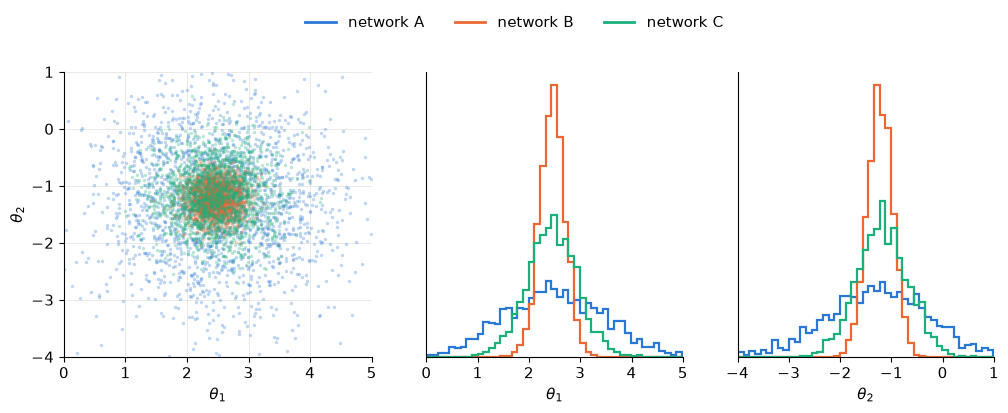

In [16]:
networks = tu.load_three_networks()      # {"A": network, "B": network, "C": network}

plot_posteriors([net.sample((2000,), x=x_o) for net in networks.values()],
                [f"network {name}" for name in networks], limits=[[0, 5], [-4, 1]]);

They disagree, and each of them looks like a reasonable posterior. Which width is the right one? In a real problem there is no answer key to settle it, so in this part **the answer key is off limits**. What you always have is the simulator.

The idea of a **coverage check**: if a posterior is right, the parameter that was used to simulate a data set falls inside the posterior's 90% interval nine times out of ten, and inside its 50% interval every second time. An overconfident posterior misses more often. An underconfident one misses less often.

The cell below shows how to get an interval from samples.

**Challenge.** Find out which network is which, with the simulator and a coverage check. Everything you need has appeared by now: `prior.sample()`, `simulator(theta)`, `network.sample((500,), x=...)`, and `torch.quantile`.

**Passes when** all three labels are right.

In [17]:
# The 90% interval of θ₁ that network A reports for x_o: 5% of its samples lie below it, 5% above
samples_A = networks["A"].sample((2000,), x=x_o)
low, high = torch.quantile(samples_A[:, 0], torch.tensor([0.05, 0.95]))
print(f"network A says: with 90% probability θ₁ lies between {low:.2f} and {high:.2f}")

network A says: with 90% probability θ₁ lies between 0.96 and 4.07


In [18]:
def coverage(network, num_tests=300):
    """How often do the 50% and the 90% interval of θ₁ contain the θ₁ that produced the data?"""
    hits_50 = hits_90 = 0
    for _ in range(num_tests):
        theta_star = prior.sample()                       # a parameter we know ...
        x_star = simulator(theta_star)                    # ... and data simulated with it
        samples_star = network.sample((500,), x=x_star)   # what the network says about that data
        q05, q25, q75, q95 = torch.quantile(samples_star[:, 0], torch.tensor([0.05, 0.25, 0.75, 0.95]))
        hits_50 += int(q25 <= theta_star[0] <= q75)
        hits_90 += int(q05 <= theta_star[0] <= q95)
    return hits_50 / num_tests, hits_90 / num_tests

coverages = {name: coverage(net) for name, net in networks.items()}
for name, (c50, c90) in coverages.items():
    print(f"network {name}: the 50% interval contains the truth in {c50:.0%} of the tests, the 90% interval in {c90:.0%}")

network A: the 50% interval contains the truth in 74% of the tests, the 90% interval in 96%
network B: the 50% interval contains the truth in 27% of the tests, the 90% interval in 59%
network C: the 50% interval contains the truth in 49% of the tests, the 90% interval in 91%


In [19]:
# A correct 50% interval contains the truth in 50% of the tests. With 300 tests that count is
# uncertain by about 3 points, so anything between 40% and 60% is fine.
labels = {name: "overconfident" if c50 < 0.4 else "underconfident" if c50 > 0.6 else "fine"
          for name, (c50, c90) in coverages.items()}
print(labels)

check_calibration(labels)

{'A': 'underconfident', 'B': 'overconfident', 'C': 'fine'}
✅ PASS · Part 4 · which network lies · all three labels are right


**Why it works.** For data you simulate yourself, you know the parameter behind it. A correct 90% interval contains that parameter in 90% of such tests, and a correct 50% interval in 50%, by definition of the posterior. The check needs no answer key and no likelihood, only the simulator and the network.

Measured with 1,000 tests per network, which pins each number to about one point:

| Network | 50% interval contains the truth | 90% interval contains the truth | Verdict |
| --- | --- | --- | --- |
| A | 74% | 96% | too wide: underconfident |
| B | 27% | 61% | too narrow: overconfident |
| C | 49% | 87% | fine |

*Looking at the widths is not enough.* The first plot shows that A is the widest and B the narrowest, but not which width is right: all three could be too narrow. Only the test against simulated data fixes the scale.

*The 50% level is the sharper test.* At the 90% level the underconfident network and the fine one are only 9 points apart, and with 300 tests each count is uncertain by about 2 points. At the 50% level they are 25 points apart. A coverage check at several levels says more than one at a single level.

*Why is A not at 100%?* Because of the walls of the prior. Near a wall the wide posterior is cut off and piles up against it, so its central interval misses parameters that sit right at the wall. Even the exact posterior of a simulator with noise 1.0 would reach only 98% and 77% here; away from the walls it would reach 99.9% and 83%.

*Why is C at 87% and not at 90%?* (The 300 tests above are too few to show it; 1,000 are enough.) That is not the prior. A correct posterior has exactly 90% coverage with any prior, bounded or not: the answer key does. The missing three points are the error of this network: a flow cannot reproduce the sharp cut at the walls, and is a little too narrow there. So "fine" means fine, not perfect, and the coverage check is sensitive enough to see the difference.

# The three networks were trained with the wrong simulator on purpose: A with noise 1.0, B with noise 0.25, C with the true noise 0.5. A network can only be as right as the simulator it learned from.

`sbi` has this check built in, for all confidence levels at once: `run_sbc` and `run_tarp` in `sbi.diagnostics`, with `sbc_rank_plot` in `sbi.analysis`.

**Message of Part 4.** A posterior can be tested with the simulator alone. If it is right, the parameters used to simulate a data set fall inside its 90% region nine times out of ten. An overconfident posterior misses more often, an underconfident one less. Coverage is necessary, not sufficient: the prior itself passes this check.

## Part 5 · Pin θ down (13 min)

One noisy point leaves θ uncertain by ±0.5. Now you get 100 points, all simulated independently with the same hidden θ. With more data the posterior has to get narrower.

In [20]:
x_iid = tu.load_toy_observations()        # shape (100, 2); the first point is the x_o you know
print(x_iid.shape)

torch.Size([100, 2])


**The obstacle.** Your NPE network was trained on one point per θ. It cannot take five:

In [21]:
try:
    posterior.sample((1000,), x=x_iid[:5])
except Exception as error:
    print("NPE says:", error)

separate = posterior.sample_batched((1000,), x=x_iid[:5], show_progress_bars=False)
print("\nsample_batched returns shape", tuple(separate.shape), "- five separate posteriors, one per point, not one for all five")

NPE says: .sample() supports only `batchsize == 1`. If you intend to sample multiple observations, use `.sample_batched()`. If you intend to sample i.i.d. observations, set up the posterior density estimator with an appropriate permutation invariant embedding net.

sample_batched returns shape (1000, 5, 2) - five separate posteriors, one per point, not one for all five


**The switch.** Neural *likelihood* estimation (NLE) learns the other conditional: $q(x \mid \theta)$, the likelihood of **one** observation. Independent observations multiply, so their log-likelihoods add:

$$\log p(\theta \mid x_1, \dots, x_n) = \log p(\theta) + \sum_{i=1}^{n} \log q(x_i \mid \theta) + \text{const.}$$

NLE trains on the same pairs $(\theta, x)$ as NPE. What it gives you is a function you can evaluate, not a sampler, so `sbi` draws the posterior samples with MCMC. This worked cell trains NLE on your training set from Part 2 and asks it about the first five observations.

 Neural network successfully converged after 147 epochs.

Generating 20 MCMC inits via resample strategy:   0%|          | 0/20 [00:00<?, ?it/s]

Running vectorized MCMC with 20 chains:   0%|          | 0/2400 [00:00<?, ?it/s]

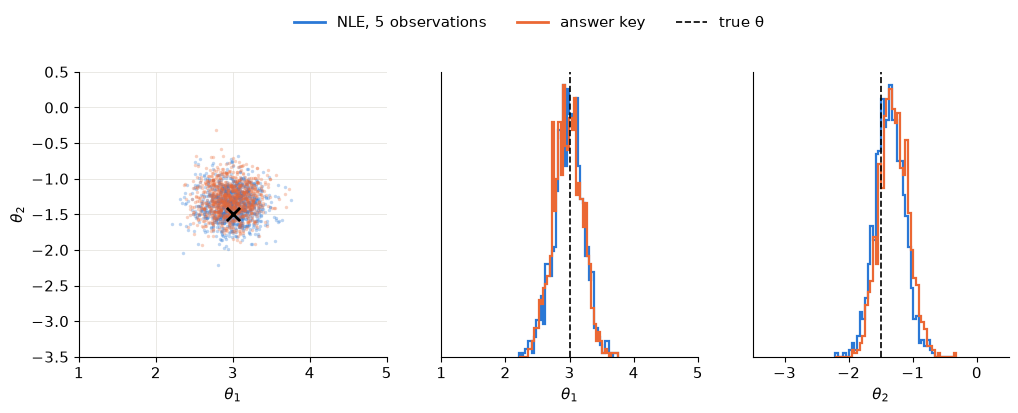

In [22]:
# 4. Training: the same pairs (theta, x) as in Part 2, a different conditional
inference = NLE(prior=prior, density_estimator="mdn")
inference.append_simulations(theta, x).train()
posterior_nle = inference.build_posterior(
    mcmc_method="slice_np_vectorized",
    mcmc_parameters=dict(num_chains=20, thin=1, warmup_steps=20),
)

# 5. Inference: the observation is now a stack of points, shape (n, 2)
n = 5
samples_nle = posterior_nle.sample((1000,), x=x_iid[:n])

plot_posteriors([samples_nle, ExactPosterior(x_iid[:n]).sample((1000,))],
                [f"NLE, {n} observations", "answer key"], truth=theta_true, limits=[[1, 5], [-3.5, 0.5]]);

`ExactPosterior(x_iid[:n])` is the answer key for the first n points, and `interval_width(samples)` returns the width of the 90% interval of each parameter.

**Challenge.** Produce one plot of how confident the posterior is against the number of observations: the width of its 90% interval for n from 1 to 100, with the answer key on top. Then read off your plot how many observations it takes to get the standard deviation of θ₁ down to 0.1.

**Passes when** the plot covers at least five values of n between 1 and 100, your widths stay within 25% of the answer key's, and your reading of n is right. For each n use the first n points, `x_iid[:n]`.

If your widths drift away from the answer key, improve the NLE training until they pass. (Short on time? `theta, x = tu.load_toy_training_set()` hands you 10,000 simulated pairs, and `posterior_nle = tu.load_toy_nle()` an NLE posterior trained on them.)

In [23]:
# NLE trained on the 2,000 pairs of Part 2 is often 10 to 25% too wide. More simulations fix it.
theta, x = tu.load_toy_training_set()                # 10,000 pairs; simulating them here works just as well

inference = NLE(prior=prior, density_estimator="mdn")
inference.append_simulations(theta, x).train()
posterior_nle = inference.build_posterior(
    mcmc_method="slice_np_vectorized",
    mcmc_parameters=dict(num_chains=20, thin=1, warmup_steps=20),
)

 Neural network successfully converged after 96 epochs.

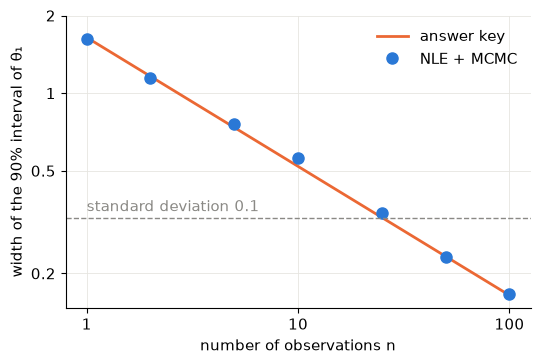

In [24]:
n_values = [1, 2, 5, 10, 25, 50, 100]
widths, exact_widths = [], []
for n in n_values:
    samples_n = posterior_nle.sample((1000,), x=x_iid[:n], show_progress_bars=False)
    widths.append(interval_width(samples_n)[0])                 # 90% interval of θ₁
    exact_widths.append(ExactPosterior(x_iid[:n]).width()[0])

# A Gaussian with standard deviation 0.1 has a 90% interval of width 2 × 1.645 × 0.1 = 0.33
target_width = 2 * 1.645 * 0.1

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(n_values, exact_widths, "-", lw=2, color=tu.C_KEY, label="answer key")
ax.plot(n_values, widths, "o", ms=8, color=tu.C_YOURS, label="NLE + MCMC")
ax.axhline(target_width, color=tu.C_MUTED, ls="--", lw=1)
ax.text(1, target_width * 1.06, "standard deviation 0.1", color=tu.C_MUTED)
ax.set(xscale="log", yscale="log", xlabel="number of observations n",
       ylabel="width of the 90% interval of θ₁")
ax.set_xticks([1, 10, 100], labels=["1", "10", "100"])
ax.set_yticks([0.2, 0.5, 1, 2], labels=["0.2", "0.5", "1", "2"])
ax.minorticks_off()
ax.legend();

In [25]:
n_needed = 25         # the answer key crosses the dashed line at n = 25: 0.5 / sqrt(25) = 0.1

check_iid(n_values, widths, n_needed)

✅ PASS · Part 5 · pin θ down · widths within 8% of the answer key, worst at n = 10 (target ≤ 25%); n for a standard deviation of 0.1 is right


**Why it works.** On the log-log plot the widths fall on a straight line of slope −1/2: the posterior narrows as $1/\sqrt{n}$. The standard deviation is $0.5/\sqrt{n}$, so it reaches 0.1 at n = 25, where the 90% interval is 0.33 wide.

NLE never saw more than one point per θ during training. Because it learned the likelihood of a single observation, any number of observations can be combined by adding log-likelihoods, with no new simulations and no retraining.

*Why the first attempt drifts.* Trained on the 2,000 pairs of Part 2, the learned likelihood is often a little too wide, and the posterior inherits that at every n: its intervals come out 10 to 25% too wide. With a few hundred pairs they are 50% too wide. With 10,000 pairs the widths usually agree to within 10%. The width also varies from one training run to the next, by 5 to 15% even with 5,000 pairs: if a run lands outside the target, train again or simulate more. The centre is less forgiving than the width: a small bias in the learned likelihood shifts the posterior by a fixed amount, and at n = 100 the posterior is only 0.05 wide, so the same shift that was invisible at n = 1 is a noticeable fraction of the width.

**Message of Part 5.** NPE is tied to the data shape it was trained on. NLE learns from one observation at a time, so IID observations combine by adding log-likelihoods, with no new simulations. The posterior narrows as $1/\sqrt{n}$. The price is MCMC at inference, and errors of the learned likelihood add up over observations.

NRE (neural ratio estimation) combines observations the same way and is what Miles Cranmer's tutorial uses for this toy problem.

## Part 6 · Wrap-up (5 min)

**Say it in one sentence each:** when would you use NPE, and when NLE?

**One possible answer.**

- **NPE** when you want the posterior for one kind of observation, fast and for many observations: the network returns samples directly, with no MCMC. Its price: it is tied to the shape of the data and to the prior it was trained with.
- **NLE** when the number of observations varies or grows, or when you want to change the prior afterwards: the likelihood of a single observation is learned once and reused. Its price: MCMC for every posterior, and errors that add up over observations.

In [26]:
tu.scorecard()

Part 1 · best θ              ✅ PASS
Part 1 · furthest θ          ✅ PASS
Part 2 · match               ✅ PASS
Part 3 · hidden walls        ✅ PASS
Part 4 · which network lies  ✅ PASS
Part 5 · pin θ down          ✅ PASS

6 of 6 checks passed.


**What you did.** You ran the five steps of SBI end to end: prior, simulator, training set, training, inference. And you checked the result three ways: against the exact answer, against the limits of the training prior, and with a coverage test that needs no exact answer.

Notebook 2 repeats the same five steps on a physical problem where no answer key exists: a Brownian particle in a double well, observed as a time series.

---
## Bonus challenges

For those who finish early. Each has a check; none is needed for Notebook 2.

### Bonus 1 · Bend the simulator

Change one line of the simulator so that $x_1$ depends on $\theta_1^2$ instead of $\theta_1$. Train NPE on the new simulator and look at the posterior for $x_o$. What happened to it, and why?

**Passes when** your posterior puts between 40% and 60% of its samples on each side of $\theta_1 = 0$, with a gap in between: less than 5% of them within $|\theta_1| < 0.5$.

 Neural network successfully converged after 82 epochs.

  0%|          | 0/4000 [00:00<?, ?it/s]

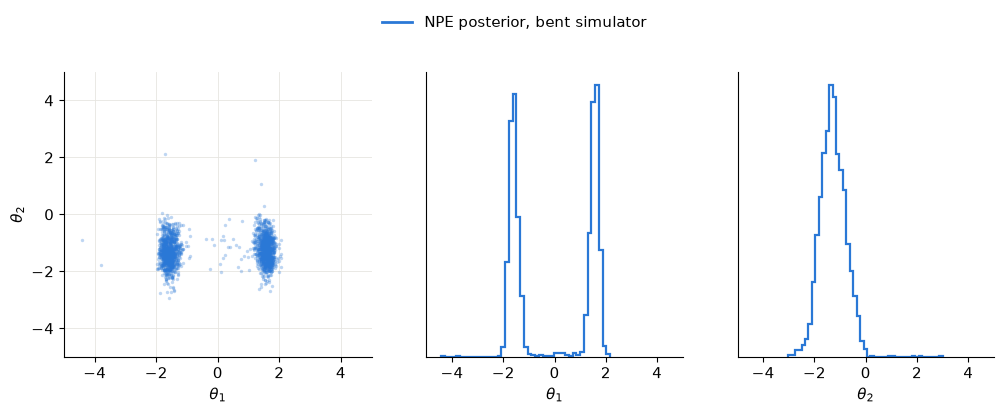

In [27]:
def simulator_bent(theta):
    bent = torch.stack([theta[..., 0] ** 2, theta[..., 1]], dim=-1)     # the one changed line
    return bent + 0.5 * torch.randn_like(theta)

theta_bent = prior.sample((5000,))
inference = NPE(prior=prior, density_estimator="nsf")
inference.append_simulations(theta_bent, simulator_bent(theta_bent)).train()
samples_bent = inference.build_posterior().sample((4000,), x=x_o)

plot_posteriors(samples_bent, "NPE posterior, bent simulator", limits=LIMITS);

In [28]:
tu.check_bimodal(samples_bent)

✅ PASS · Bonus · bend the simulator · 50% of the samples have θ₁ > 0 (target: between 40% and 60%), 1% lie in the gap |θ₁| < 0.5 (target: under 5%)


**Why it works.** The data only see $\theta_1^2$, so $+\theta_1$ and $-\theta_1$ produce the same data. The posterior has two equally heavy modes at $\theta_1 \approx \pm\sqrt{x_{o,1}} \approx \pm 1.56$. Nothing in the data can choose between them: the simulator is not identifiable in the sign of $\theta_1$.

A point estimate would report one mode, or worse their mean, $\theta_1 \approx 0$, which is a parameter the data rule out. The posterior reports both. A flow needs some flexibility to split into two modes; the spline flow (`"nsf"`) does it more cleanly than the default.

### Bonus 2 · Repair Part 3

The observation `x_far` below lies beyond the walls at ±5: with the prior of this notebook, no θ can explain it well. Retrain NPE with a prior wide enough that `x_far` gets a posterior that passes the Part 2 check.

**Passes when** the mismatch score at `x_far` is 0.55 or below, against the answer key for your new prior.

First, what your network from Part 2 says about `x_far`. Asked without a time limit, it may never answer: if none of its samples fall inside the prior, `sbi` keeps drawing. `max_sampling_time` stops that.

In [29]:
x_far = torch.tensor([7.0, -6.5])

try:
    samples_old = posterior.sample((2000,), x=x_far, max_sampling_time=5.0, return_partial_on_timeout=True)
    print(f"after at most 5 seconds: {len(samples_old)} of 2000 samples inside the prior")
except RuntimeError:
    print("after 5 seconds: not a single sample inside the prior")

  0%|          | 0/2000 [00:00<?, ?it/s]

                    accepted. It may take a long time to collect the remaining
                    2000 samples. You can prevent very long runtimes by
                    setting `max_sampling_time` to limit runtime, or disabling
                    rejection sampling (e.g. via `reject_outside_prior=False` in
                    `posterior.sample()` when available).Alternatively, consider interrupting (Ctrl-C)
                    and switching to `build_posterior(..., sample_with='mcmc')`.


after at most 5 seconds: 32 of 2000 samples inside the prior


 Neural network successfully converged after 87 epochs.

  0%|          | 0/2000 [00:00<?, ?it/s]

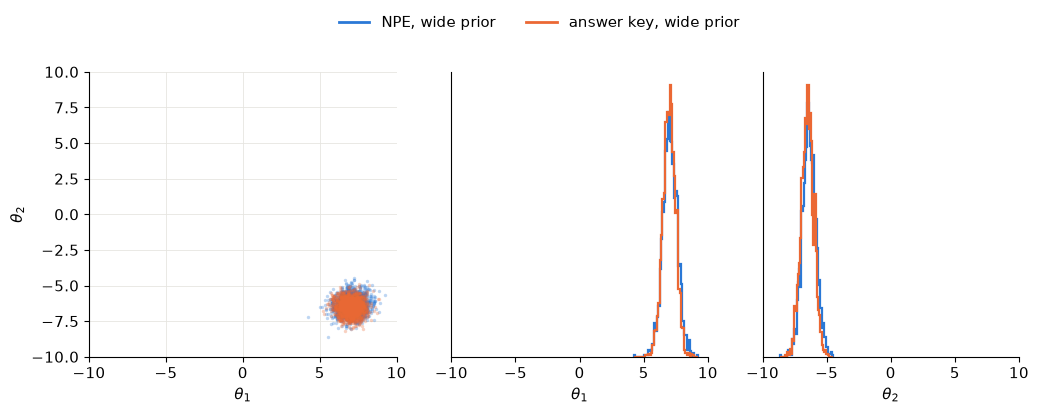

In [30]:
low, high = -10.0, 10.0
prior_wide = BoxUniform(low=low * torch.ones(2), high=high * torch.ones(2))

num_simulations_far = 4000            # the box has four times the area, so it takes about four times the simulations
theta_wide = prior_wide.sample((num_simulations_far,))
inference = NPE(prior=prior_wide)
inference.append_simulations(theta_wide, simulator(theta_wide)).train()
samples_far = inference.build_posterior().sample((2000,), x=x_far)

exact_far = ExactPosterior(x_far, low=low, high=high)
plot_posteriors([samples_far, exact_far.sample((2000,))], ["NPE, wide prior", "answer key, wide prior"],
                limits=[[-10, 10], [-10, 10]]);

In [31]:
tu.check_repair(samples_far, num_simulations_far, x_far, low=low, high=high)

✅ PASS · Bonus · repair · mismatch score 0.53 (target ≤ 0.55) with 4,000 simulations


**Why it works.** The walls of Part 3 come from the prior, so the repair is a wider prior. It has a price: the same number of simulations is now spread over four times the area, so the network sees four times fewer examples near any given observation. To keep the quality, the number of simulations has to grow with the volume of the prior. In two dimensions that is a factor of 4. In ten dimensions, doubling every range costs a factor of 1,000. This is why the choice of prior matters so much in SBI, and why sequential methods, which concentrate simulations near one observation, exist.

### Bonus 3 · Part 5 with NPE after all

NPE can take several observations if you give it an *embedding network* that turns a set of points into a fixed-size summary, the same whatever the order of the points. Follow the sbi guide [How to use permutation-invariant embeddings for iid observations](https://sbi.readthedocs.io/en/stable/how_to_guide/08_permutation_invariant_embeddings.html) and reach the Part 5 benchmark with NPE instead of NLE.

**Passes when** `check_iid` passes with widths from your NPE posterior. It is enough to cover n from 1 to 25.

In [32]:
from sbi.neural_nets.embedding_nets import FCEmbedding, PermutationInvariantEmbedding

RUN_SLOW_BONUS = True        # about 4 minutes on two CPU cores; set to False to skip

if RUN_SLOW_BONUS:
    # 3. Training set: one simulation is now a SET of points, between 1 and 50 of them.
    #    Sets of different size are padded with NaN to the common shape (50, 2).
    max_n, num_sets = 50, 20_000
    theta_sets = prior.sample((num_sets,))
    x_sets = simulator(theta_sets[:, None, :].repeat(1, max_n, 1))                      # shape (20000, 50, 2)
    set_sizes = torch.exp(torch.rand(num_sets) * np.log(max_n)).round().long().clamp(1, max_n)
    x_sets[torch.arange(max_n)[None] >= set_sizes[:, None]] = float("nan")              # small sets as often as large ones

    # 4. Training: an embedding net reads every point and sums over the set, so the order of the
    #    points cannot matter. The sum grows with the number of points, which tells the flow how
    #    many there are.
    single_point_net = FCEmbedding(input_dim=2, num_hiddens=40, num_layers=2, output_dim=10)
    embedding_net = PermutationInvariantEmbedding(single_point_net, trial_net_output_dim=10,
                                                  num_layers=2, num_hiddens=40, output_dim=10)
    density_estimator = posterior_nn("maf", embedding_net=embedding_net, z_score_x="none")
    inference = NPE(prior=prior, density_estimator=density_estimator)
    # sbi warns here that the NaNs will break the training. They will not: the embedding net masks them.
    inference.append_simulations(theta_sets, x_sets, exclude_invalid_x=False)
    estimator = inference.train(stop_after_epochs=30)

 Neural network successfully converged after 184 epochs.

✅ PASS · Bonus · NPE on sets · widths within 4% of the answer key, worst at n = 5 (target ≤ 25%); n for a standard deviation of 0.1 is right


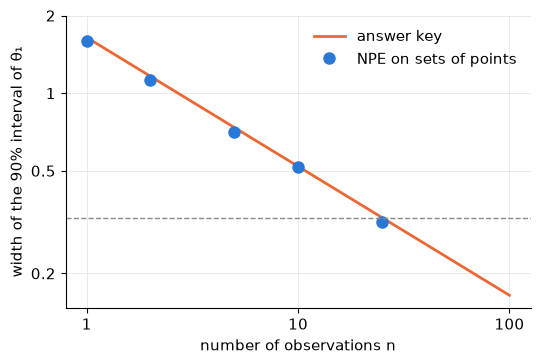

In [33]:
if RUN_SLOW_BONUS:
    # 5. Inference. posterior.sample() refuses an observation that contains NaN,
    #    so the padded observation goes to the trained flow directly.
    n_values_npe = [1, 2, 5, 10, 25]
    widths_npe = []
    for n in n_values_npe:
        x_padded = torch.full((1, max_n, 2), float("nan"))
        x_padded[0, :n] = x_iid[:n]
        with torch.no_grad():
            samples_n = estimator.sample((2000,), condition=x_padded).squeeze(1)
        widths_npe.append(interval_width(samples_n)[0])

    fig, ax = plt.subplots(figsize=(6, 3.8))
    ax.plot(n_values, exact_widths, "-", lw=2, color=tu.C_KEY, label="answer key")
    ax.plot(n_values_npe, widths_npe, "o", ms=8, color=tu.C_YOURS, label="NPE on sets of points")
    ax.axhline(target_width, color=tu.C_MUTED, ls="--", lw=1)
    ax.set(xscale="log", yscale="log", xlabel="number of observations n",
           ylabel="width of the 90% interval of θ₁")
    ax.set_xticks([1, 10, 100], labels=["1", "10", "100"])
    ax.set_yticks([0.2, 0.5, 1, 2], labels=["0.2", "0.5", "1", "2"])
    ax.minorticks_off()
    ax.legend()

    check_iid(n_values_npe, widths_npe, n_needed, key="Bonus · NPE on sets")

**Why it works, and where it stops.** The embedding net turns a set of points into a fixed-size summary that does not depend on their order, so one NPE network can take 1 point or 25. For the benchmark that is enough: the widths for n up to 25 come out within 10% of the answer key, and n = 25 can be read off.

It took some care to get there, and the care is the lesson.

- *Twenty times the simulated points of Part 5.* NLE learned the likelihood of one point from 10,000 points. Here 20,000 sets hold about 250,000 points, and it takes four minutes to train instead of ten seconds.
- *Train beyond the range you need.* A network trained on sets of up to 25 points was 20% to 100% too wide at n = 25, the edge of what it had seen. Trained on up to 50, it is fine at 25.
- *It does not reach n = 100.* Trained on sets of up to 100 points, the same network was 30% too wide at n = 50 and 80% too wide at n = 100. Three times the simulations, with a mixture density network in place of the flow, did no better. At n = 100 the posterior is 200 times narrower than the prior, and NPE has to learn that sharpness from examples. NLE gets it for free: it adds log-likelihoods.

So NPE on sets is the right tool when the number of observations is small or fixed and you want posteriors without MCMC. When it varies over orders of magnitude, learn the likelihood of one observation instead.

*All numbers above are from single runs or a few seeds; expect them to move.* One more caveat for the curious: `PermutationInvariantEmbedding` also passes the size of each set to its second network, but in sbi 0.27.0 that number is wrong for points with more than one coordinate when several sets are processed in one batch (set i receives the size of set i // 2). The network still learns the size from the sum. In one paired run with the sizes corrected by hand, the result at n = 25 was the same and the result at n = 50 somewhat better.

### Bonus 4 · NLE against NRE

Neural ratio estimation (NRE) learns the ratio $p(x \mid \theta) / p(x)$ with a classifier and combines IID observations the same way as NLE. `NRE` is in `sbi.inference` and is used like `NLE`. Run it on the Part 5 benchmark and compare the two.

**Passes when** `check_iid` passes with widths from your NRE posterior.

In [34]:
from sbi.inference import NRE

inference = NRE(prior=prior)
inference.append_simulations(theta, x).train()                    # the same 10,000 pairs as NLE
posterior_nre = inference.build_posterior(
    mcmc_method="slice_np_vectorized",
    mcmc_parameters=dict(num_chains=20, thin=1, warmup_steps=20),
)

 Neural network successfully converged after 47 epochs.

✅ PASS · Bonus · NRE · widths within 12% of the answer key, worst at n = 2 (target ≤ 25%); n for a standard deviation of 0.1 is right


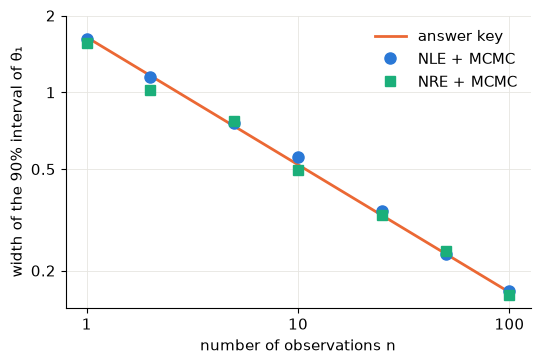

In [35]:
widths_nre = []
for n in n_values:
    samples_n = posterior_nre.sample((1000,), x=x_iid[:n], show_progress_bars=False)
    widths_nre.append(interval_width(samples_n)[0])

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(n_values, exact_widths, "-", lw=2, color=tu.C_KEY, label="answer key")
ax.plot(n_values, widths, "o", ms=8, color=tu.C_YOURS, label="NLE + MCMC")
ax.plot(n_values, widths_nre, "s", ms=7, color=tu.C_OTHER, label="NRE + MCMC")
ax.set(xscale="log", yscale="log", xlabel="number of observations n",
       ylabel="width of the 90% interval of θ₁")
ax.set_xticks([1, 10, 100], labels=["1", "10", "100"])
ax.set_yticks([0.2, 0.5, 1, 2], labels=["0.2", "0.5", "1", "2"])
ax.minorticks_off()
ax.legend()

check_iid(n_values, widths_nre, n_needed, key="Bonus · NRE")

**What to see.** NRE passes the same benchmark on the same 10,000 pairs: its widths stay within 10 to 20% of the answer key. It gets there by another route. Instead of a density estimator it trains a classifier: given an x and several candidate θ, which θ was x simulated with? What the classifier learns is the likelihood ratio, and ratios of independent observations multiply just like likelihoods.

One thing the benchmark does not test is the centre of the posterior. In three runs of ours, the NRE posterior at n = 100 sat up to 2.5 of its own standard deviations away from the centre of the answer key, and the offset grew with n. That is the price named in Part 5: a small error in what the network learned about one observation is added up a hundred times. The more observations you combine, the more carefully the single-observation network has to be trained and checked.